In [10]:
import uproot
import pandas
import numpy as np
import os

import ipympl

from scipy import interpolate
import scipy

import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.colors as mplColors

uproot.__version__

'5.0.8'

['air', 'lxe', 'lxe2', 'cf4', 'green', 'red', 'test']


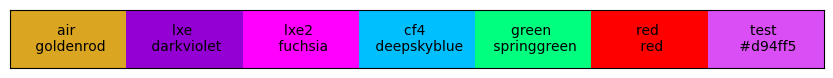

In [18]:
class StyleThing:
  def __init__(self, color, linestyle):
    self.col = color
    self.ls = linestyle
    
class MyStyleSet:
  def __init__(self, option = "nobles"):
    
    # medium types. these are what populate the other arrays 
    self.air = StyleThing('goldenrod', '-')
    
    self.lxe = StyleThing('darkviolet', '-')
    self.lxe2 = StyleThing('fuchsia', '-')

    self.cf4 = StyleThing('deepskyblue', '-')
    # self.cf4_2 = StyleThing('deepskyblue', '-')
    
    self.green = StyleThing('springgreen', '-')
    
    self.red = StyleThing('red', '-')
    
    self.test = StyleThing('#d94ff5', '-')
    
    # line styles
    self.line1 = "-"
    self.line2 = "--"
    self.line3 = "-."
    
    # all colors
    self.names = [x for x in self.__dict__.keys() if isinstance(self.__dict__[x], StyleThing)]
    self.allColsStr = [x.col for x in self.__dict__.values() if isinstance(x, StyleThing)]
    self.allColsObj = mplColors.to_rgba_array(self.allColsStr).reshape(1, -1, 4)
    
  def show(self):
    fig, ax = plt.subplots(figsize = (len(self.names)*1.5, 2))
    ax.set_xticks([])
    ax.set_yticks([])
    ax.imshow(self.allColsObj, aspect=0.5)
    for i, (color, name) in enumerate(zip(self.allColsStr, self.names)):
      txt = f"{name} \n {color}"
      ax.text(i, 0, txt, ha='center', va='center')
    plt.show()
    return

ms = MyStyleSet()

# show it off
ms.lxe.col
print(ms.names)

ms.show()
cycleCols = [ms.air.col, ms.lxe2.col, ms.cf4.col, ms.green.col, ms.red.col, ms.test.col]
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=cycleCols)

In [19]:
rootPath4 = "../outputs_v4_finalTesting/"
rootPath4question = "../outputs_v4_finalTesting/questionableOutput/"

# final data
pname = "final results"
fileAir = uproot.open(os.path.join(rootPath4, "final_air_N5e5_110-1050nm_0-85deg.root"))
fileCF4 = uproot.open(os.path.join(rootPath4, "final_lcf4_N1e5_110-1050nm_0-85deg.root"))
filelxe = uproot.open(os.path.join(rootPath4, "final_lxe_N1e5_110-1050nm_0-85deg.root"))

ttAir = fileAir["simOutput"]
ttcf4 = fileCF4["simOutput"]
ttlxe = filelxe["simOutput"]

In [20]:
fileList = [fileAir, filelxe, fileCF4]
fNames = ["fAir", "fLXe", "fCF4"]

## getting trees
ttlist = [f["simOutput"] for f in fileList]
dflist = [ tt.arrays(library="pd").drop_duplicates() for tt in ttlist ]

for df, name in zip(dflist, fNames):
  df["eff"] = df["fNinBulk"]/df["fNphoton"]
  df["pde"] = df["fNinBulkPDE"]/df["fNphoton"]
  df["ref"] = 1-df["eff"]
  df.loc[:, "dfName"] = name

dfAir = dflist[0]
dfCF4 = dflist[1]
dfLXe = dflist[2]
  
angles = dfAir['fAngle'].unique()
print("Angles:", angles)
column_names = ["fNphoton", "fPhotonWln", "fAngle", "fNonWindow", "fNonSurface", "fNonBulk", "fNinBulk", "fNinBulkPDE"]

dfAir.head(5)

Angles: [ 0.         39.49999688 57.09999983 71.60024383 85.00000778]


,fNphoton,fPhotonWln,fAngle,fNonWindow,fNonSurface,fNonBulk,fNinBulk,fNinBulkPDE,eff,pde,ref,dfName
0,500000,110.012598,0.000000,0,221026,193820,197059,90333,0.394118,0.180666,0.605882,fAir
1,500000,110.012598,39.499997,0,215929,199261,189972,86950,0.379944,0.173900,0.620056,fAir
2,500000,110.012598,57.100000,0,215351,199727,176616,80718,0.353232,0.161436,0.646768,fAir
3,500000,110.012598,71.600244,0,238728,176733,158977,73125,0.317954,0.146250,0.682046,fAir
4,500000,110.012598,85.000008,0,331096,84146,101948,46836,0.203896,0.093672,0.796104,fAir


In [14]:
# to find what you want
closestAngle = lambda df, angle: df["fAngle"].unique()[np.abs(df["fAngle"].unique() - angle).argmin()]
closestWlen = lambda df, wlen: df["fPhotonWln"].unique()[np.abs(df["fPhotonWln"].unique() - wlen).argmin()]

getDfforAngle = lambda df, angle: df[df["fAngle"] == closestAngle(df, angle)]
getDfforWlen = lambda df, wlen: df[df["fPhotonWln"] == closestWlen(df, wlen)]

removeDuplicates = lambda df, name = "fPhotonWln": df.loc[~df[name].duplicated(keep=False), :]

Text(0.5, 1.0, 'PDE vs. Wavelength for Angle = 40 deg')

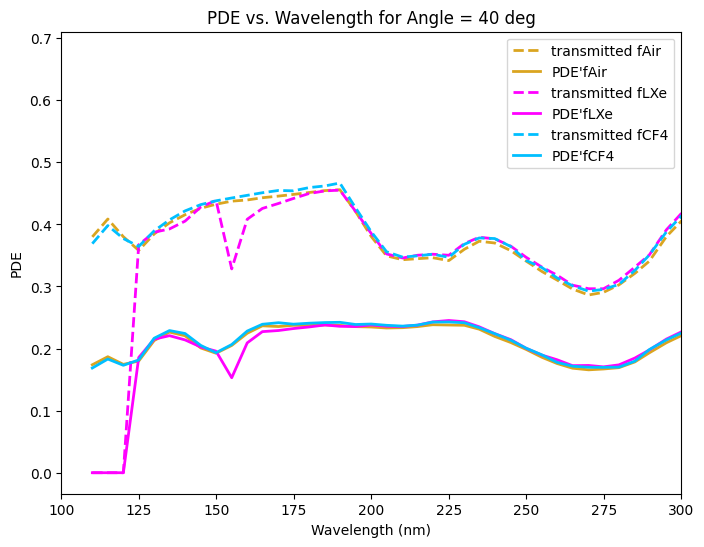

In [28]:

angleWanted = 40
fig, ax = plt.subplots(1, 1, figsize=(8, 6))

for i, df in enumerate(dflist):
  colUse = cycleCols[i]
  
  df_plot = getDfforAngle(df, angleWanted)
  dfName = df_plot.dfName.unique()[0]
  
  ax.plot(df_plot.fPhotonWln, df_plot.eff, linewidth=2, linestyle = "--", label="transmitted " + dfName, color = colUse)
  ax.plot(df_plot.fPhotonWln, df_plot.pde, linewidth=2, label="PDE'"+ dfName, color=colUse)

ax.set_xlim(100, 300)
ax.legend()
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("PDE")
ax.set_title("PDE vs. Wavelength for Angle = {} deg".format(angleWanted))

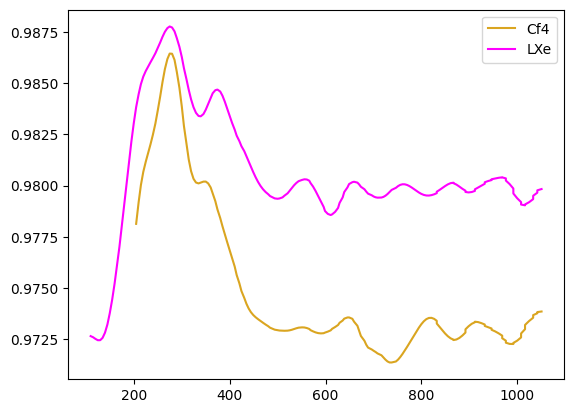

In [33]:
from scipy.ndimage import gaussian_filter1d
angleWanted = 0
dfAir0 = getDfforAngle(dfAir, angleWanted)
dfCF40 = getDfforAngle(dfCF4, angleWanted)
dfLXe = getDfforAngle(dfLXe, angleWanted)

correction_cf4 = dfAir0.eff/dfCF40.eff
sm_correction_cf4 = gaussian_filter1d(correction_cf4, sigma=4)

correction_lxe = dfAir0.eff/dfLXe.eff
sm_correction_lxe = gaussian_filter1d(correction_lxe, sigma=4)

plt.plot(dfAir0.fPhotonWln, sm_correction_cf4, label='Cf4')
plt.plot(dfAir0.fPhotonWln, sm_correction_lxe, label='LXe')
plt.legend()
plt.show()

# plt.plot(dfCF40['x'], dfCF40['y'], label='CF4')